# Internet Aesthetics-- Text Analysis + Modeling

1. Tags (motifs + colours + values) --> TF-IDF → topics + clusters
2. Overview text → TF-IDF → topics + clusters
3. Unexpected neighbours-- close aesthetics the wiki doesn't link
4. Can the text predict the era? — `MultinomialNB`
5. Map for the final piece-- t-SNE --> JSON

## Setup

In [5]:
!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/data_utils.py" -O data_utils.py
!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/text_utils.py" -O text_utils.py

In [9]:
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

from data_utils import display_confusion_matrix, distance_score, balance_score, silhouette_score
from text_utils import get_top_words

loads the clean table

In [10]:
# fillna("") -> empty text instead of NaN, so string checks work
aes_df = pd.read_csv("data/clean/aesthetics_clean.csv").fillna("")
hf_df = pd.read_parquet("data/raw/aesthetics_wiki.parquet")

print("same order:", list(hf_df["title"]) == list(aes_df["title"]))
aes_df["description"] = hf_df["description"].fillna("").values

print(aes_df.shape)
display(aes_df.head())

same order: True
(1022, 13)


/tmp/ipykernel_14989/2957098979.py:2: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  aes_df = pd.read_csv("data/clean/aesthetics_clean.csv").fillna("")


,title,decade,decade_source,era,split,motifs,colours,values,tags_text,n_tags,overview,overview_words,description
0,Mallsoft,2010.0,hugging face,Tumblr,train,"shopping malls (empty and full), mall food, ma...","pink, teal, mint green, purple, black, white, ...","shop till you drop, exploration",shopping malls (empty and full) mall food ma...,18,Mallsoft's approach to shopping malls is based...,26,Mallsoft\n\n\n\n\nShop... till you drop.\n\n\n...
1,Femme Fatale,1940.0,hugging face,pre-internet,train,"mystery, intelligence, beauty, seduction, power","red, black, dark green, dark blue, metallic tones","enticement, scheming, heartlessness, lust",mystery intelligence beauty seduction powe...,14,"The ""Femme Fatale"" trope is a collection of im...",27,Femme Fatale\n\n\n\n\nBlack Widow (played by S...
2,Indicolite,2020.0,hugging face,TikTok,train,"diamonds, water, clouds, vintage statues","blue, indigo, cyan, white, grey",,diamonds water clouds vintage statues blue ...,9,The 'Indicolite' aesthetic is based on the aes...,49,"Indicolite\n\n\n\n\n\n\nOther names\nGlaucous,..."
3,Kingcore,,none,unknown,none,"control, leadership, war, crowns, royal lifest...","gold, royal blue, black, white, purple, red","power, money, hedonism, conquest, status, duty...",control leadership war crowns royal lifest...,22,The 'Kingcore' aesthetic is based on the theme...,34,"Kingcore\n\n\n\n\n\n\nKey motifs\nControl, lea..."
4,Onii Kei,1990.0,zenodo,Old Web,test,,,,,0,Japanese fashion is often referred to as 'Onii...,60,Onii Kei Onii Kei (literal elder brother style...


### Custom stop words -- similar to the movie review

In [11]:
stop_list = ["aesthetic", "aesthetics", "style", "styles", "core", "known", "based", "associated",
             "key", "motifs", "colours", "colors", "values", "related", "media", "brands", "decade", "origin",
             "file", "jpg", "png"]

for i in range(2030):
  stop_list.append(str(i))
  stop_list.append(str(i) + "s")

custom_stop_words = list(ENGLISH_STOP_WORDS.union(stop_list))
print(len(custom_stop_words), "stop words")

4399 stop words


---
# 1. Tags

Only aesthetics that have tags. `min_df=5`: a word must appear in at least 5 aesthetics. `max_df=0.5`: drop words used by more than half.

In [12]:
tag_df = aes_df[aes_df["tags_text"] != ""].reset_index(drop=True)

tag_vec = TfidfVectorizer(stop_words=custom_stop_words, min_df=5, max_df=0.5, ngram_range=(1, 1))
# ngram_range=(1, 2) -> keeps phrases like "pastel pink" and "neon lights" together

tag_vct = tag_vec.fit_transform(tag_df["tags_text"])

tag_vocab = tag_vec.get_feature_names_out()
print(tag_vct.shape)
print(tag_vocab[:50])

(943, 602)
['3d' 'abandoned' 'abstract' 'academic' 'accents' 'acceptance'
 'accessories' 'activism' 'activities' 'adventure' 'alcohol' 'alienation'
 'ambition' 'american' 'ancient' 'androgyny' 'angels' 'animal' 'animals'
 'animation' 'anime' 'anti' 'appearance' 'appreciation' 'architecture'
 'areas' 'art' 'artistic' 'arts' 'attire' 'attitude' 'auroras'
 'authenticity' 'authoritarianism' 'awareness' 'baby' 'bad' 'balance'
 'band' 'bats' 'beach' 'beaches' 'beauty' 'beige' 'big' 'black' 'blood'
 'blue' 'blues' 'body']


### Topics (SVD)

top words of each SVD component.

In [13]:
tag_svd = TruncatedSVD(n_components=8, random_state=1010)
tag_svd.fit(tag_vct)

tag_topics = get_top_words(tag_svd.components_, tag_vocab, n_words=8)
for i in range(len(tag_topics)):
  print("topic", i, tag_topics[i])

topic 0 ['black', 'white', 'red', 'blue', 'green', 'grey', 'pink', 'brown']
topic 1 ['pink', 'neon', 'bright', 'purple', 'pastels', 'yellow', 'pastel', 'red']
topic 2 ['black', 'red', 'white', 'grey', 'silver', 'shock', 'value', 'violence']
topic 3 ['yellow', 'blue', 'red', 'green', 'orange', 'purple', 'gold', 'cold']
topic 4 ['dark', 'red', 'yellow', 'imagery', 'culture', 'bright', 'art', 'humor']
topic 5 ['neon', 'green', 'grey', 'purple', 'black', 'blue', 'dark', 'rainbow']
topic 6 ['dark', 'purple', 'gold', 'pink', 'silver', 'elegance', 'mystery', 'crystals']
topic 7 ['neon', 'gold', 'silver', 'tones', 'brown', 'black', 'earth', 'orange']


### How many clusters?

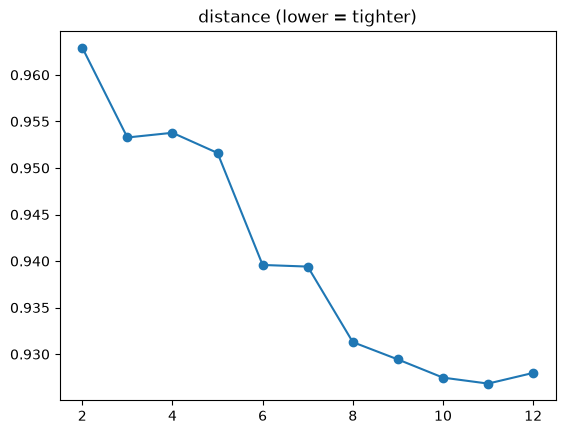

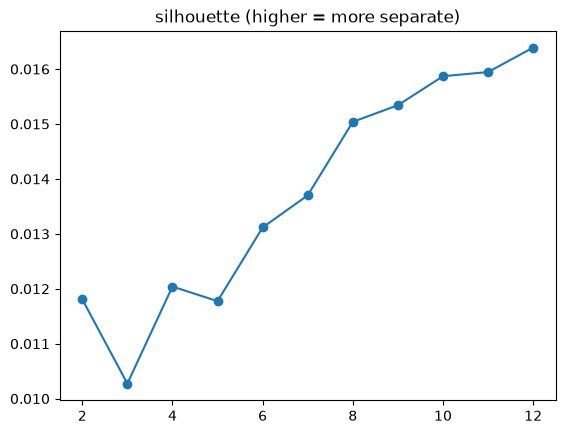

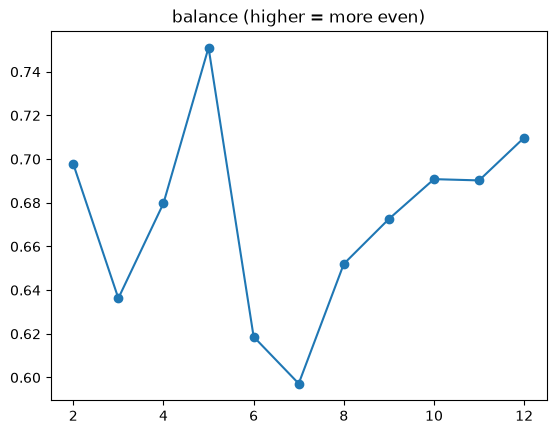

In [14]:
tag_dense = tag_vct.toarray()

ks = list(range(2, 13))
dist_scores = []
sil_scores = []
bal_scores = []

for k in ks:
  pred = KMeans(n_clusters=k, random_state=1010).fit_predict(tag_vct)
  dist_scores.append(distance_score(tag_dense, pred))
  sil_scores.append(silhouette_score(tag_dense, pred))
  bal_scores.append(balance_score(pred))

plt.plot(ks, dist_scores, marker="o")
plt.title("distance (lower = tighter)")
plt.show()
plt.plot(ks, sil_scores, marker="o")
plt.title("silhouette (higher = more separate)")
plt.show()
plt.plot(ks, bal_scores, marker="o")
plt.title("balance (higher = more even)")
plt.show()

`TAG_K` from the plots. Cluster centers are "average aesthetics", and `get_top_words()` shows their top words.

In [15]:
TAG_K = 8

tag_km = KMeans(n_clusters=TAG_K, random_state=1010)
tag_df["tag_cluster"] = tag_km.fit_predict(tag_vct)

tag_cluster_words = get_top_words(tag_km.cluster_centers_, tag_vocab, n_words=8)

for c in range(TAG_K):
  in_c = tag_df[tag_df["tag_cluster"] == c]
  print("CLUSTER", c, "-", len(in_c), "aesthetics")
  print("  words:", tag_cluster_words[c])
  print("  e.g.:", list(in_c["title"].head(8)))
  print("  eras:", list(in_c["era"].value_counts().index[:3]))
  print()

CLUSTER 0 - 405 aesthetics
  words: ['bright', 'neon', 'culture', 'black', 'art', 'social', 'self', 'white']
  e.g.: ['Hands Up', 'Cheiron Crush', 'Pin-up', 'LOLcore', 'The Box 96', 'New Rave', 'Kawaii', 'Interceltic']
  eras: ['pre-internet', 'unknown', 'Web 2.0']

CLUSTER 1 - 97 aesthetics
  words: ['pink', 'white', 'blue', 'purple', 'black', 'pastel', 'pastels', 'red']
  e.g.: ['Yandere', 'Unicorncore', 'Synthwave', '2020 Alt', 'Delicate Sweet', 'Cherry Emoji Twitter', 'Baddie', 'Lunarpunk']
  eras: ['Tumblr', 'unknown', 'pre-internet']

CLUSTER 2 - 27 aesthetics
  words: ['horror', 'blood', 'black', 'death', 'red', 'crosses', 'white', 'purple']
  e.g.: ['Trad Goth', 'Kimoicore', 'Mythpunk', 'Welwitschia Goth', 'Halloween', 'Catholic Horror', 'Dethereal', 'Digital Oddity']
  eras: ['unknown', 'Tumblr', 'pre-internet']

CLUSTER 3 - 63 aesthetics
  words: ['dark', 'black', 'red', 'green', 'brown', 'blue', 'grey', 'mystery']
  e.g.: ['Femme Fatale', 'Electronic Body Music', 'Coffinwood

---
# 2. Overview Text

In [16]:
lang_vec = TfidfVectorizer(stop_words=custom_stop_words, min_df=3, max_df=0.5, ngram_range=(1, 1))
# try-- ngram_range=(1, 2)

lang_vct = lang_vec.fit_transform(aes_df["overview"])

lang_vocab = lang_vec.get_feature_names_out()
print(lang_vct.shape)

(1022, 1049)


In [17]:
lang_svd = TruncatedSVD(n_components=20, random_state=1010)
lang_svd_feats = lang_svd.fit_transform(lang_vct)

lang_topics = get_top_words(lang_svd.components_[:8], lang_vocab, n_words=8)
for i in range(len(lang_topics)):
  print("topic", i, lang_topics[i])

topic 0 ['despite', 'combination', 'elements', 'music', 'art', 'characterized', 'movement', 'themes']
topic 1 ['despite', 'lack', 'fact', 'clear', 'people', 'emergence', 'able', 'movement']
topic 2 ['combination', 'despite', 'lack', 'elements', 'clear', 'characterized', 'various', 'differences']
topic 3 ['art', 'movement', 'combination', 'artistic', 'artists', 'modern', 'inspiration', 'realism']
topic 4 ['music', 'popular', 'popularity', 'design', 'combination', 'late', 'emergence', 'influenced']
topic 5 ['music', 'themes', 'genre', 'influenced', 'various', 'art', 'dance', 'combination']
topic 6 ['people', 'fact', 'term', 'used', 'range', 'popular', 'nature', 'able']
topic 7 ['elements', 'lack', 'clear', 'art', 'visual', 'combines', 'blend', 'inspiration']


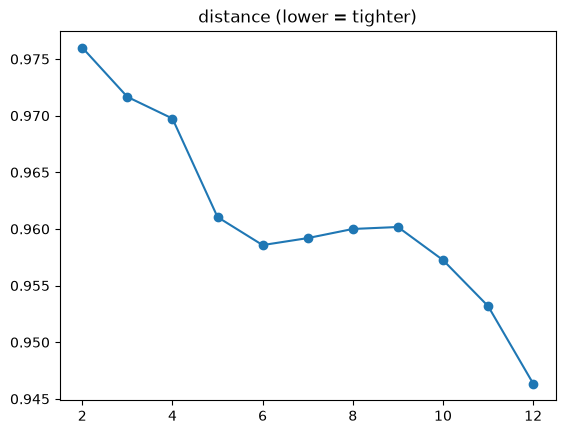

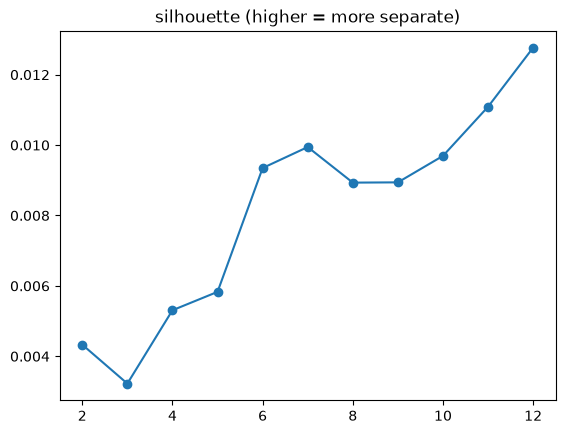

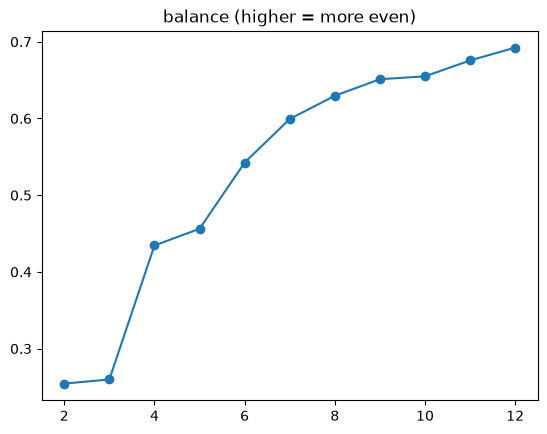

In [18]:
lang_dense = lang_vct.toarray()

dist_scores = []
sil_scores = []
bal_scores = []

for k in ks:
  pred = KMeans(n_clusters=k, random_state=1010).fit_predict(lang_vct)
  dist_scores.append(distance_score(lang_dense, pred))
  sil_scores.append(silhouette_score(lang_dense, pred))
  bal_scores.append(balance_score(pred))

plt.plot(ks, dist_scores, marker="o")
plt.title("distance (lower = tighter)")
plt.show()
plt.plot(ks, sil_scores, marker="o")
plt.title("silhouette (higher = more separate)")
plt.show()
plt.plot(ks, bal_scores, marker="o")
plt.title("balance (higher = more even)")
plt.show()

In [19]:
LANG_K = 8

lang_km = KMeans(n_clusters=LANG_K, random_state=1010)
aes_df["lang_cluster"] = lang_km.fit_predict(lang_vct)

lang_cluster_words = get_top_words(lang_km.cluster_centers_, lang_vocab, n_words=8)

for c in range(LANG_K):
  in_c = aes_df[aes_df["lang_cluster"] == c]
  print("CLUSTER", c, "-", len(in_c), "aesthetics")
  print("  words:", lang_cluster_words[c])
  print("  e.g.:", list(in_c["title"].head(8)))
  print("  eras:", list(in_c["era"].value_counts().index[:3]))
  print()

CLUSTER 0 - 41 aesthetics
  words: ['american', 'vintage', 'architecture', 'nostalgia', 'modern', 'united', 'art', 'range']
  e.g.: ['Indicolite', 'Onii Kei', 'Barber Salon', 'Vintage Americana', 'Regional Gothic', 'By Category', 'Historical Americana', 'Vintage British Sportsman']
  eras: ['unknown', 'pre-internet', 'Old Web']

CLUSTER 1 - 66 aesthetics
  words: ['movement', 'art', 'artistic', 'despite', 'cultural', 'influenced', 'traditional', 'garde']
  e.g.: ['New Rave', 'Interceltic', 'Avant Basic', 'Bohemian', 'Mexican Muralism', 'Normcore', 'Earthy Black Girl', 'Surrealism']
  eras: ['pre-internet', 'unknown', 'Web 2.0']

CLUSTER 2 - 111 aesthetics
  words: ['combination', 'elements', 'characterized', 'visual', 'various', 'described', 'accessories', 'practical']
  e.g.: ['Hexatron', '2020 Alt', 'Delicate Sweet', 'Gamercore', 'Nuclear', 'Post-Rock', 'Dungeoncore', 'Golden Hour']
  eras: ['unknown', 'Tumblr', 'pre-internet']

CLUSTER 3 - 58 aesthetics
  words: ['culture', 'technol

---
# 3. Unexpected Neighbours

For each favourite: the 5 closest aesthetics by overview text (Euclidean distance on the 20 SVD features, same as `dist()`), and whether the wiki links them.

In [20]:
edges_df = pd.read_csv("data/raw/wiki_ecosystem_edges.csv")

linked = set()
for a, b in zip(edges_df["aesthetic"], edges_df["related"]):
  linked.add((a, b))
  linked.add((b, a))

names = list(aes_df["title"])

In [21]:
favorites = ["Vaporwave", "Frutiger Aero", "Webcore", "Weirdcore", "Dreamcore", "Seapunk"]

for fav in favorites:
  i = names.index(fav)

  dists = []
  for j in range(len(names)):
    s = 0
    for a, b in zip(lang_svd_feats[i], lang_svd_feats[j]):
      s += (a - b) ** 2
    dists.append(s ** 0.5)

  closest = pd.Series(dists).sort_values().index[1:6]   # [0] is itself

  neighbours = []
  for j in closest:
    if (fav, names[j]) in linked:
      neighbours.append(names[j])
    else:
      neighbours.append(names[j] + " (NOT linked)")

  print(fav, "->", neighbours)

Vaporwave -> ['Wehraboo (NOT linked)', 'Y2K Futurism', 'HexD', 'Ostalgie (NOT linked)', 'Apache (NOT linked)']
Frutiger Aero -> ['Raggare (NOT linked)', 'Club Kids (NOT linked)', 'Vectorflourish', 'Playboy (NOT linked)', 'Cryptidcore (NOT linked)']
Webcore -> ['Lolicore (NOT linked)', 'Basque Radical Rock (NOT linked)', 'Krushclub (NOT linked)', 'Hyperpop (NOT linked)', 'Electronic Body Music (NOT linked)']
Weirdcore -> ['Emo Rap (NOT linked)', 'Pride flags (NOT linked)', 'Motomami (NOT linked)', 'Cluttercore (NOT linked)', 'Incel (NOT linked)']
Dreamcore -> ['Biopunk (NOT linked)', 'Honeycore (NOT linked)', 'Nautical (NOT linked)', 'Sizz (NOT linked)', 'Taisho Roman (NOT linked)']
Seapunk -> ['Skater (NOT linked)', 'Ocean Grunge', '90s Cool (NOT linked)', 'Kandi Raver (NOT linked)', 'Breakcore (NOT linked)']


---
# 4. Can the Text Predict the Era?

In [22]:
era_df = aes_df[aes_df["era"] != "unknown"]
print(era_df["era"].value_counts())

min_count = era_df["era"].value_counts().min()

def sample_min(df):
  return df.sample(min_count, random_state=1010)

rg = era_df.groupby("era")
era_balanced_df = rg[era_df.columns].apply(sample_min).reset_index(drop=True)

era_train_df, era_test_df = train_test_split(era_balanced_df, test_size=0.2, random_state=1010)

print("balanced:", min_count, "per era -", len(era_train_df), "train /", len(era_test_df), "test")
print("random guess:", round(1 / era_balanced_df["era"].nunique(), 3))

era
pre-internet    283
Tumblr          148
Web 2.0         101
Old Web          82
TikTok           81
Name: count, dtype: int64
balanced: 81 per era - 324 train / 81 test
random guess: 0.2


### Bag-of-words + Naive Bayes

train accuracy: 0.923
test accuracy: 0.395


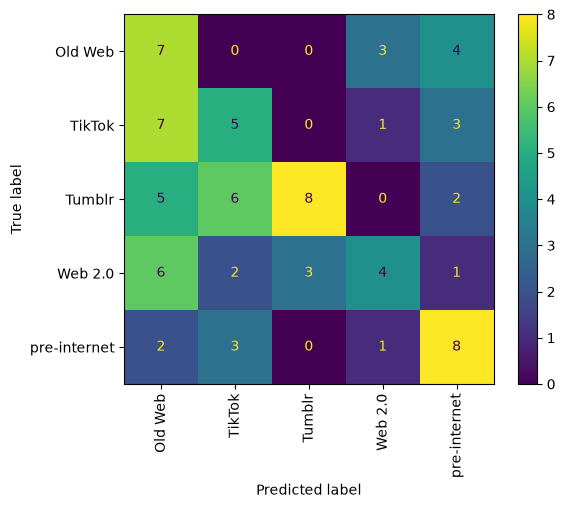

In [23]:
TEXT_COL = "overview"
# "tags_text" or "description"

era_vec = TfidfVectorizer(stop_words=custom_stop_words, min_df=2, max_df=0.75, ngram_range=(1, 1))
# CountVectorizer instead of TfidfVectorizer
# ngram_range=(1, 2) or (2, 2)

era_model = MultinomialNB()
#era_model = RandomForestClassifier()

era_train_vct = era_vec.fit_transform(era_train_df[TEXT_COL])
era_test_vct = era_vec.transform(era_test_df[TEXT_COL])

era_model.fit(era_train_vct, era_train_df["era"])

train_preds = era_model.predict(era_train_vct)
test_preds = era_model.predict(era_test_vct)

print("train accuracy:", round(accuracy_score(era_train_df["era"], train_preds), 3))
print("test accuracy:", round(accuracy_score(era_test_df["era"], test_preds), 3))

era_labels = sorted(era_balanced_df["era"].unique())
display_confusion_matrix(era_test_df["era"], test_preds, era_labels)

Top words of each era: join all of an era's texts into one big text, vectorize it, `get_top_words()`.

In [24]:
era_vocab = era_vec.get_feature_names_out()

for era in era_labels:
  era_text = " ".join(era_balanced_df[era_balanced_df["era"] == era][TEXT_COL])
  print(era, get_top_words(era_vec.transform([era_text]), era_vocab, n_words=10))

Old Web ['despite', 'music', 'british', 'late', 'popular', 'influenced', 'elements', 'term', 'fashion', 'video']
TikTok ['academia', 'trend', 'pursuit', 'blend', 'focus', 'girl', 'knowledge', 'elements', 'combination', 'real']
Tumblr ['combination', 'themes', 'nature', 'academia', 'elements', 'people', 'theatre', 'focus', 'approach', 'japanese']
Web 2.0 ['themes', 'despite', 'elements', 'combination', 'punk', 'anime', 'music', 'popular', 'design', 'people']
pre-internet ['extreme', 'girl', 'art', 'despite', 'movement', 'focus', 'social', 'culture', 'boy', 'design']


---
# 5. Map

t-SNE on the 20 SVD features → 2D, coloured by cluster and by era.

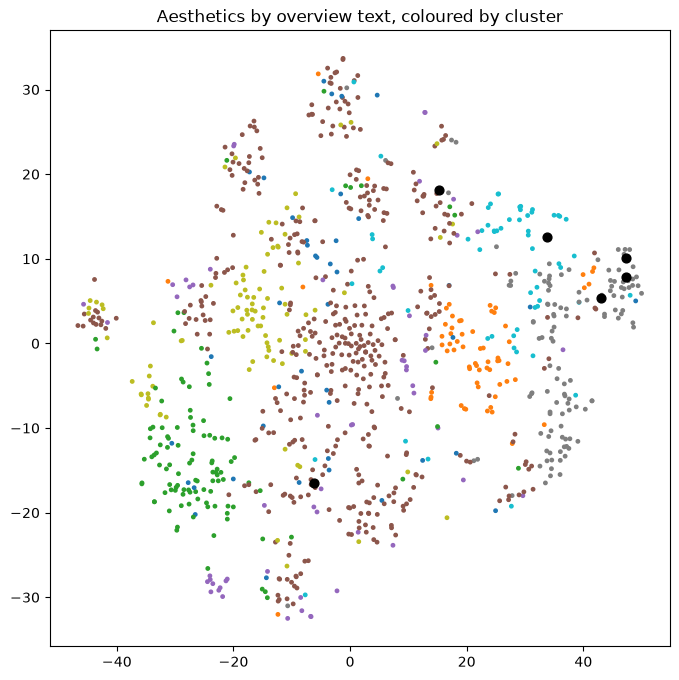

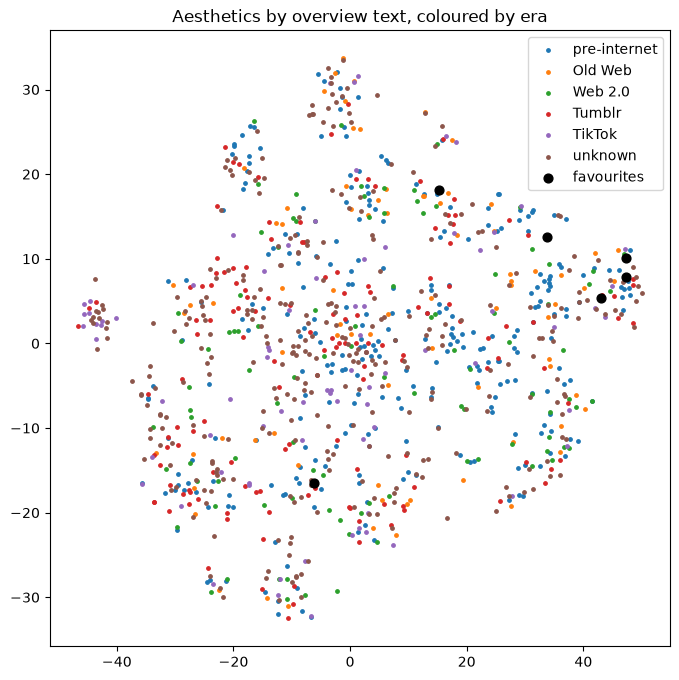

,title,map_x,map_y,lang_cluster,era
295,Dreamcore,-6.242192,-16.444212,4,Tumblr
548,Webcore,47.294544,10.091338,5,Old Web
712,Seapunk,15.308502,18.137035,5,Web 2.0
809,Weirdcore,42.966328,5.335151,4,Tumblr
884,Vaporwave,47.251526,7.841692,5,Tumblr
938,Frutiger Aero,33.694035,12.598330,7,Web 2.0


In [25]:
tsne = TSNE(n_components=2, random_state=1010).set_output(transform="pandas")
map_df = tsne.fit_transform(lang_svd_feats)

aes_df["map_x"] = map_df["tsne0"].values
aes_df["map_y"] = map_df["tsne1"].values
fav_df = aes_df[aes_df["title"].isin(favorites)]

plt.figure(figsize=(8, 8))
plt.scatter(aes_df["map_x"], aes_df["map_y"], c=aes_df["lang_cluster"], cmap="tab10", s=6)
plt.scatter(fav_df["map_x"], fav_df["map_y"], c="black", s=40)
plt.title("Aesthetics by overview text, coloured by cluster")
plt.show()

era_order = ["pre-internet", "Old Web", "Web 2.0", "Tumblr", "TikTok", "unknown"]

plt.figure(figsize=(8, 8))
for era in era_order:
  in_era = aes_df[aes_df["era"] == era]
  plt.scatter(in_era["map_x"], in_era["map_y"], s=6, label=era)
plt.scatter(fav_df["map_x"], fav_df["map_y"], c="black", s=40, label="favourites")
plt.legend()
plt.title("Aesthetics by overview text, coloured by era")
plt.show()

display(fav_df[["title", "map_x", "map_y", "lang_cluster", "era"]])

In [26]:
!mkdir -p output

map_cols = ["title", "era", "decade", "map_x", "map_y", "lang_cluster", "motifs", "colours", "values", "overview"]
aes_df[map_cols].to_csv("output/aesthetics_map.csv", index=False)

print(aes_df[map_cols].shape)

(1022, 10)
